In [31]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt


In [32]:
def create_mask(image_size, x, y, radius=8):
    mask = np.zeros(image_size, dtype=np.uint8)
    cv2.circle(mask, (int(x), int(y)), radius, 255, -1)
    return mask


In [33]:
class LungNoduleSegmentationDataset(Dataset):
    def __init__(self, root_dir, split="train"):
        self.image_dir = os.path.join(root_dir, "images", split)
        self.label_dir = os.path.join(root_dir, "labels", split)
        self.images = sorted(os.listdir(self.image_dir))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]

        # ---- Load image ----
        img_path = os.path.join(self.image_dir, img_name)
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (256, 256))
        image = image / 255.0

        # ---- Load label (YOLO FORMAT) ----
        base_name = os.path.splitext(img_name)[0]
        label_path = os.path.join(self.label_dir, base_name + ".txt")

        with open(label_path, "r") as f:
            line = f.readline().strip().split()

            # YOLO format: class x y w h
            x_norm = float(line[1])
            y_norm = float(line[2])

        # ---- Convert normalized → pixel ----
        x = int(x_norm * 256)
        y = int(y_norm * 256)

        # ---- Safety clamp ----
        x = np.clip(x, 0, 255)
        y = np.clip(y, 0, 255)

        # ---- Create mask ----
        mask = create_mask((256, 256), x, y, radius=8)
        mask = mask / 255.0

        image = np.expand_dims(image, axis=0)
        mask = np.expand_dims(mask, axis=0)

        return (
            torch.tensor(image, dtype=torch.float32),
            torch.tensor(mask, dtype=torch.float32),
        )


In [34]:
root_dir = "C:/Users/sanja/Desktop/Dataset/ct_images"

train_dataset = LungNoduleSegmentationDataset(root_dir, split="train")
val_dataset   = LungNoduleSegmentationDataset(root_dir, split="val")


In [35]:
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False)


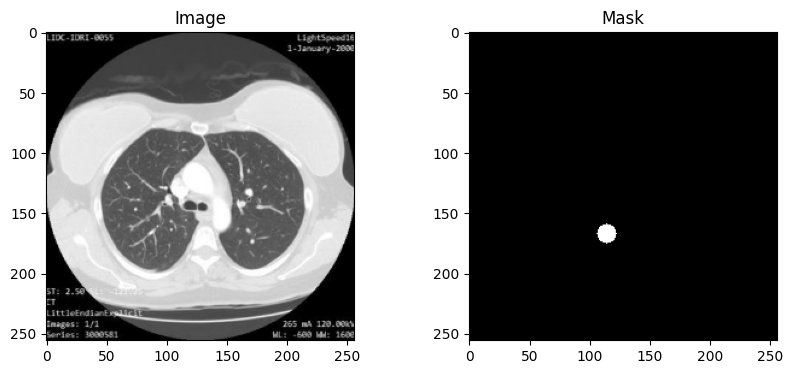

In [36]:
image, mask = train_dataset[0]

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(image[0], cmap="gray")
plt.title("Image")

plt.subplot(1,2,2)
plt.imshow(mask[0], cmap="gray")
plt.title("Mask")

plt.show()
